In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("apache-spark-neo4j-connector")
    .master("local[*]")
    .config("spark.jars.packages", "org.neo4j.connectors:spark:6.1.2-s_2.13")
    .config("neo4j.url", "bolt://neo4j:7687")
    .config("neo4j.authentication.basic.username", "neo4j")
    .config("neo4j.authentication.basic.password", "password")
    .getOrCreate()
)

In [2]:
runtime = spark._jvm.java.lang.Runtime.getRuntime()

def to_mb(value):
    return round(value / 1024 / 1024, 2)

print("JVM max memory:", to_mb(runtime.maxMemory()), "MB")
print("JVM allocated memory:", to_mb(runtime.totalMemory()), "MB")
print("JVM used memory:", to_mb(runtime.totalMemory() - runtime.freeMemory()), "MB")
print("Available JVM processors:", runtime.availableProcessors())

JVM max memory: 1024.0 MB
JVM allocated memory: 118.0 MB
JVM used memory: 70.69 MB
Available JVM processors: 8


In [3]:
from pyspark.sql import functions as F

trips_raw = spark.read.parquet(
    "/workspace/data/yellow_tripdata_2026-06.parquet"
)

zones_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("/workspace/data/taxi_zone_lookup.csv")
)

trips_raw.printSchema()
print(trips_raw.count())
zones_raw.printSchema()
print(zones_raw.count())

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)
 |-- request_source: string (nullable = true)

3837248
root
 |-- LocationID:

In [4]:
trips = (
    trips_raw
    .select(
        trips_raw.PULocationID.alias("pickup_location_id"),
        trips_raw.DOLocationID.alias("dropoff_location_id"),
        trips_raw.tpep_pickup_datetime.alias("pickup_datetime"),
        trips_raw.tpep_dropoff_datetime.alias("dropoff_datetime"),
        trips_raw.trip_distance,
        trips_raw.fare_amount,
        trips_raw.tip_amount,
        trips_raw.passenger_count
    ).na.drop()
    .filter(trips_raw.passenger_count > 0)
    .withColumn(
        "duration_minutes",
        ((
            F.col("dropoff_datetime")
            - F.col("pickup_datetime")
        ) / 60).cast("long")
    )
)

print(f"Liczba przejazdów po przygotowaniu: {trips.count()} / {trips_raw.count()}")
trips.printSchema()
trips.show()

Liczba przejazdów po przygotowaniu: 2813332 / 3837248
root
 |-- pickup_location_id: integer (nullable = true)
 |-- dropoff_location_id: integer (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- duration_minutes: long (nullable = true)

+------------------+-------------------+-------------------+-------------------+-------------+-----------+----------+---------------+----------------+
|pickup_location_id|dropoff_location_id|    pickup_datetime|   dropoff_datetime|trip_distance|fare_amount|tip_amount|passenger_count|duration_minutes|
+------------------+-------------------+-------------------+-------------------+-------------+-----------+----------+---------------+----------------+
|               140|                238|2026-06-01 00:

In [5]:
trips_agg = (
    trips
    .groupBy(
        "pickup_location_id",
        "dropoff_location_id"
    )
    .agg(
        F.count("*").alias("trip_count"),
        
        F.avg("trip_distance").alias("avg_distance"),
        F.avg("duration_minutes").alias("avg_duration_minutes"),
        F.avg("fare_amount").alias("avg_fare"),
        F.avg("tip_amount").alias("avg_tip"),
    )
)

trips_agg.printSchema()
print(trips_agg.count())
trips_agg.show(10, truncate=False)

root
 |-- pickup_location_id: integer (nullable = true)
 |-- dropoff_location_id: integer (nullable = true)
 |-- trip_count: long (nullable = false)
 |-- avg_distance: double (nullable = true)
 |-- avg_duration_minutes: double (nullable = true)
 |-- avg_fare: double (nullable = true)
 |-- avg_tip: double (nullable = true)

17427
+------------------+-------------------+----------+------------------+--------------------+------------------+------------------+
|pickup_location_id|dropoff_location_id|trip_count|avg_distance      |avg_duration_minutes|avg_fare          |avg_tip           |
+------------------+-------------------+----------+------------------+--------------------+------------------+------------------+
|148               |229                |415       |3.2369397590361446|15.86987951807229   |18.287951807228918|3.531566265060242 |
|75                |200                |5         |9.214             |26.2                |40.94             |8.276             |
|163               

In [6]:
zones = zones_raw.select(
    zones_raw.LocationID.alias("location_id"),
    zones_raw.Borough.alias("borough"),
    zones_raw.Zone.alias("zone")
)

print(f"Liczba stref: {zones.count()}")

Liczba stref: 265


In [7]:
(
    zones.write
    .format("org.neo4j.spark.DataSource")
    .mode("Overwrite")
    .option("labels", ":TaxiZone")
    .option("node.keys", "location_id")
    .option("batch.size", "1000")
    .save()
)

In [8]:
props = ",".join(filter(lambda x: not x.endswith("id"), trips_agg.columns))
props

'trip_count,avg_distance,avg_duration_minutes,avg_fare,avg_tip'

In [9]:
(
    trips_agg
    .repartition(1).write
    .format("org.neo4j.spark.DataSource")
    .mode("Append")
    .option("relationship", "TRIP_AGG")
    .option("relationship.save.strategy", "keys")

    # Początkowy węzeł relacji
    .option("relationship.source.save.mode", "Match")
    .option("relationship.source.labels", ":TaxiZone")
    .option("relationship.source.node.keys", "pickup_location_id:location_id")

    # Końcowy węzeł relacji
    .option("relationship.target.save.mode", "Match")
    .option("relationship.target.labels", ":TaxiZone")
    .option("relationship.target.node.keys", "dropoff_location_id:location_id")

    # Właściwości relacji
    .option(
        "relationship.properties",
        props
    )
    .option("batch.size", "1000")
    .save()
)

In [10]:
(
    spark.read.format("org.neo4j.spark.DataSource")
    .option("query", """
        CALL gds.graph.drop('taxi-trips-agg', false)
        YIELD graphName
        RETURN graphName
    """)
    .option("partitions", "1")
    .load()
    .show(truncate=False)
)

(
    spark.read.format("org.neo4j.spark.DataSource")
    .option("gds", "gds.graph.project")
    .option("gds.graphName", "taxi-trips-agg")
    .option("gds.nodeProjection", "TaxiZone")
    .option("gds.relationshipProjection", "TRIP_AGG")
    .option("gds.configuration.relationshipProperties", "trip_count")
    .load()
    .show(truncate=False)
)

+---------+
|graphName|
+---------+
+---------+

+--------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------+---------+-----------------+-------------+
|nodeProjection                                    |relationshipProjection                                                                                                                                                                                  |graphName     |nodeCount|relationshipCount|projectMillis|
+--------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------+---------+-----------------+-------------+
|{TaxiZone -> {"pr

In [11]:
query = """
CALL gds.pageRank.stream('taxi-trips-agg', {
    relationshipWeightProperty: 'trip_count',
    maxIterations: 20,
    dampingFactor: 0.85
})
YIELD nodeId, score

WITH gds.util.asNode(nodeId) AS zone, score

RETURN
    zone.location_id AS locationId,
    zone.zone AS zone,
    score

ORDER BY score DESC
"""

pagerank_df = (
    spark.read.format("org.neo4j.spark.DataSource")
    .option("query", query)
    .option("partitions", "1")
    .load()
)

pagerank_df.show(15, truncate=False)

+----------+-------------------------+------------------+
|locationId|zone                     |score             |
+----------+-------------------------+------------------+
|265       |Outside of NYC           |8.926412863584728 |
|236       |Upper East Side North    |6.427752654143818 |
|237       |Upper East Side South    |6.022367545495395 |
|1         |Newark Airport           |5.786361021574159 |
|132       |JFK Airport              |4.80463433548045  |
|161       |Midtown Center           |4.7793250043800395|
|239       |Upper West Side South    |4.160557658819571 |
|230       |Times Sq/Theatre District|4.028224312455437 |
|142       |Lincoln Square East      |3.9070335082180576|
|170       |Murray Hill              |3.9025073442192495|
|162       |Midtown East             |3.8702547804563863|
|141       |Lenox Hill West          |3.703114130093522 |
|238       |Upper West Side North    |3.564464627721161 |
|68        |East Chelsea             |3.368689131696826 |
|163       |Mi

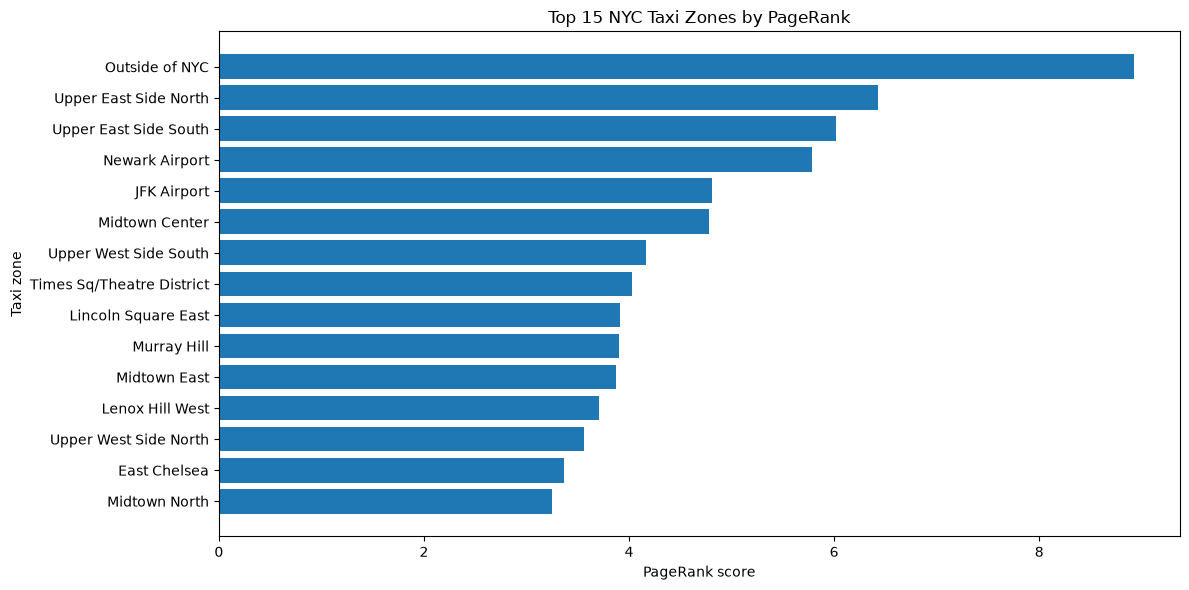

In [12]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

top_zones = (
    pagerank_df
    .orderBy(F.desc("score"))
    .limit(15)
    .toPandas()
)

plt.figure(figsize=(12, 6))
plt.barh(top_zones["zone"], top_zones["score"])
plt.xlabel("PageRank score")
plt.ylabel("Taxi zone")
plt.title("Top 15 NYC Taxi Zones by PageRank")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [13]:
(
    spark.read.format("org.neo4j.spark.DataSource")
    .option("query", """
        CALL gds.graph.drop('taxi-communities', false)
        YIELD graphName
        RETURN graphName
    """)
    .option("partitions", "1")
    .load()
    .show(truncate=False)
)

(
    spark.read.format("org.neo4j.spark.DataSource")
    .option("gds", "gds.graph.project")
    .option("gds.graphName", "taxi-communities")
    .option("gds.nodeProjection", "TaxiZone")
    .option("gds.relationshipProjection", {
        "TRIP_AGG": {
            "orientation": "UNDIRECTED",
            "properties": {                            
                "trip_count": {                
                    "property": "trip_count",              
                    "aggregation": "SUM"     
                }
            }
        }
    })
    .load()
    .show(truncate=False)
)

+---------+
|graphName|
+---------+
+---------+

+--------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------+---------+-----------------+-------------+
|nodeProjection                                    |relationshipProjection                                                                                                                                                                                 |graphName       |nodeCount|relationshipCount|projectMillis|
+--------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------+---------+-----------------+-------------+
|{TaxiZone -> {

In [14]:
louvain_query = """
CALL gds.louvain.stream('taxi-communities', {
    relationshipWeightProperty: 'trip_count',
    maxLevels: 10
})
YIELD nodeId, communityId

WITH gds.util.asNode(nodeId) AS zone, communityId

RETURN
    zone.location_id AS locationId,
    zone.zone AS zone,
    zone.borough AS borough,
    communityId

ORDER BY communityId
"""

louvain_df = (
    spark.read.format("org.neo4j.spark.DataSource")
    .option("query", louvain_query)
    .option("partitions", "1")
    .load()
)

louvain_df.show(30, truncate=False)

+----------+---------------------------------------------+-------------+-----------+
|locationId|zone                                         |borough      |communityId|
+----------+---------------------------------------------+-------------+-----------+
|264       |N/A                                          |Unknown      |67         |
|103       |Governor's Island/Ellis Island/Liberty Island|Manhattan    |102        |
|104       |Governor's Island/Ellis Island/Liberty Island|Manhattan    |103        |
|105       |Governor's Island/Ellis Island/Liberty Island|Manhattan    |104        |
|2         |Jamaica Bay                                  |Queens       |131        |
|3         |Allerton/Pelham Gardens                      |Bronx        |131        |
|5         |Arden Heights                                |Staten Island|131        |
|6         |Arrochar/Fort Wadsworth                      |Staten Island|131        |
|7         |Astoria                                      |Queens 

In [15]:
from pyspark.sql import functions as F

community_sizes = (
    louvain_df
    .groupBy("communityId")
    .agg(
        F.count("*").alias("zoneCount"),
        F.collect_list("zone").alias("zones")
    )
    .orderBy(F.desc("zoneCount"))
)

community_sizes.show(20, truncate=True)

+-----------+---------+--------------------+
|communityId|zoneCount|               zones|
+-----------+---------+--------------------+
|        131|      193|[Jamaica Bay, All...|
|        169|       32|[Alphabet City, B...|
|        238|       23|[Newark Airport, ...|
|        236|       13|[East Harlem Nort...|
|        103|        1|[Governor's Islan...|
|        104|        1|[Governor's Islan...|
|         67|        1|               [N/A]|
|        102|        1|[Governor's Islan...|
+-----------+---------+--------------------+



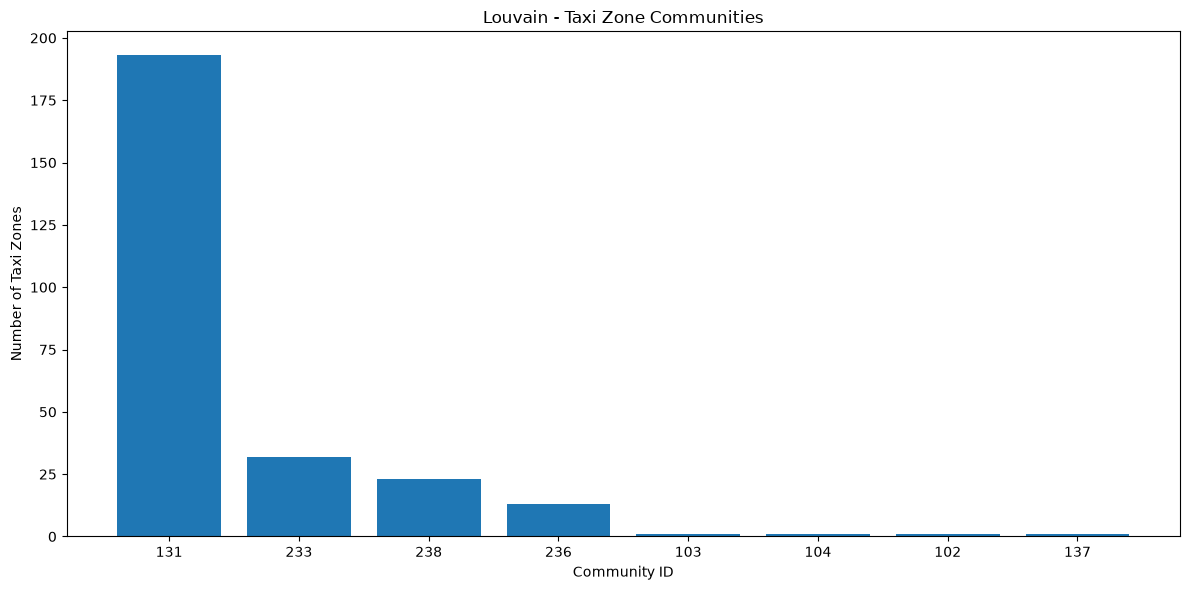

In [16]:
import matplotlib.pyplot as plt

plot_df = community_sizes.toPandas()

plt.figure(figsize=(12, 6))
plt.bar(
    plot_df["communityId"].astype(str),
    plot_df["zoneCount"]
)

plt.xlabel("Community ID")
plt.ylabel("Number of Taxi Zones")
plt.title("Louvain - Taxi Zone Communities")
plt.tight_layout()
plt.show()